# Road Infrastructure Analysis — US Accidents Dataset

**Axis 4 — Is road infrastructure associated with lower risk?**


---


## 0. Imports and data loading

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.multivariate.manova import MANOVA

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)


In [ ]:
from pathlib import Path

DATA_DIR = Path("D:/US/Dataset")   
DATA_PATH = DATA_DIR / "US_Accidents_Sample500k_Clean.csv"

df = pd.read_csv(DATA_PATH)
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")

Shape: 500,000 rows x 32 columns


In [6]:
infra_cols = ['Traffic_Signal', 'Crossing', 'Junction', 'Stop', 'Roundabout', 'Railway']
for col in infra_cols:
    df[col] = df[col].astype(bool)

df['is_severe'] = (df['Severity'] >= 3).astype(int)

for col in infra_cols:
    print(f"{col:15s}: {df[col].mean() * 100:5.1f}% of accidents are located near this feature")


Traffic_Signal :  20.6% of accidents are located near this feature
Crossing       :  12.9% of accidents are located near this feature
Junction       :   5.4% of accidents are located near this feature
Stop           :   3.0% of accidents are located near this feature
Roundabout     :   0.0% of accidents are located near this feature
Railway        :   0.9% of accidents are located near this feature


---
## 1. Mann-Whitney test — Distance(mi) with vs without a traffic signal



U = 19919753202, p-value = 5.491e-57
Median distance WITH signal:    0.000 mi
Median distance WITHOUT signal: 0.000 mi
Common-language effect size: 0.488  (0.5 = no difference)


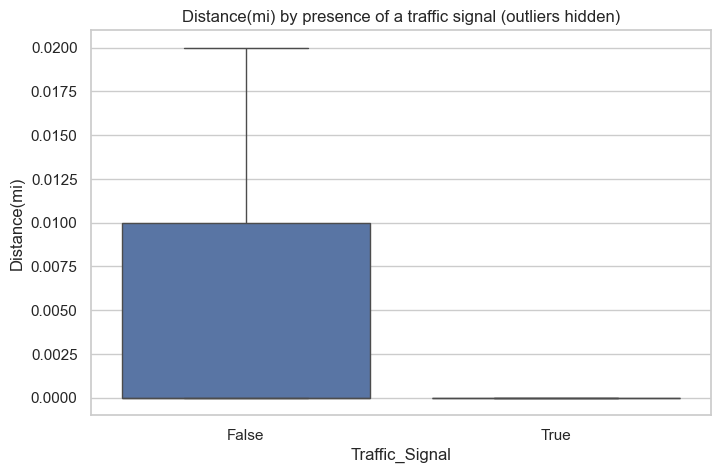

In [7]:
with_signal = df.loc[df['Traffic_Signal'], 'Distance(mi)'].dropna()
without_signal = df.loc[~df['Traffic_Signal'], 'Distance(mi)'].dropna()

u_stat, p_value = stats.mannwhitneyu(with_signal, without_signal, alternative='two-sided')
cles = u_stat / (len(with_signal) * len(without_signal))   # P(distance_with > distance_without)

print(f"U = {u_stat:.0f}, p-value = {p_value:.4g}")
print(f"Median distance WITH signal:    {with_signal.median():.3f} mi")
print(f"Median distance WITHOUT signal: {without_signal.median():.3f} mi")
print(f"Common-language effect size: {cles:.3f}  (0.5 = no difference)")

plt.figure(figsize=(8, 5))
sns.boxplot(x='Traffic_Signal', y='Distance(mi)', data=df, showfliers=False)
plt.title("Distance(mi) by presence of a traffic signal (outliers hidden)")
plt.show()


---
## 2. Multivariate logistic regression — infrastructure and severe accidents

In [8]:
model_df = df.dropna(subset=['Severity']).copy()

X = sm.add_constant(model_df[infra_cols].astype(int))
y = model_df['is_severe']

logit_model = sm.Logit(y, X).fit(disp=0)
print(logit_model.summary())


c:\Users\poste\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                           Logit Regression Results                           
Dep. Variable:              is_severe   No. Observations:               500000
Model:                          Logit   Df Residuals:                   499993
Method:                           MLE   Df Model:                            6
Date:                Sun, 25 Oct 2026   Pseudo R-squ.:                 0.08932
Time:                        18:09:30   Log-Likelihood:            -2.9426e+05
converged:                      False   LL-Null:                   -3.2312e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const             -0.3089      0.003    -89.978      0.000      -0.316      -0.302
Traffic_Signal    -1.5127      0.012   -130.044      0.000      -1.535      -1.490
Crossing          -1.0923      0.016

In [9]:
odds = np.exp(logit_model.params).rename('Odds Ratio')
ci = np.exp(logit_model.conf_int())
ci.columns = ['2.5%', '97.5%']
odds_ratios_df = pd.concat([odds, ci], axis=1).drop(index='const')
odds_ratios_df.sort_values('Odds Ratio')


c:\Users\poste\AppData\Local\Programs\Python\Python311\Lib\site-packages\pandas\core\internals\blocks.py:395: RuntimeWarning: overflow encountered in exp
  result = func(self.values, **kwargs)


,Odds Ratio,2.5%,97.5%
Roundabout,3.051356e-07,0.000000,inf
Stop,1.164238e-01,0.108819,0.124560
Traffic_Signal,2.203205e-01,0.215354,0.225401
Crossing,3.354424e-01,0.325040,0.346178
Railway,1.505056e+00,1.396148,1.622459
Junction,1.728158e+00,1.685169,1.772244


In [ ]:
rows = []
for col in infra_cols:
    rows.append({
        'feature': col,
        '% severe WITH': round(df.loc[df[col], 'is_severe'].mean() * 100, 1),
        '% severe WITHOUT': round(df.loc[~df[col], 'is_severe'].mean() * 100, 1)
    })
pd.DataFrame(rows)


,feature,% severe WITH,% severe WITHOUT
0,Traffic_Signal,10.0,41.2
1,Crossing,8.4,38.7
2,Junction,54.4,33.7
3,Stop,6.2,35.7
4,Roundabout,0.0,34.8
5,Railway,26.6,34.9


---
## 3. MANOVA — Severity and Distance(mi) jointly, by traffic signal



In [11]:
manova_df = df.dropna(subset=['Severity', 'Distance(mi)']).copy()
manova_df = manova_df.rename(columns={'Distance(mi)': 'Distance'})
manova_df['Signal'] = np.where(manova_df['Traffic_Signal'], 'With_Signal', 'No_Signal')

manova = MANOVA.from_formula('Severity + Distance ~ Signal', data=manova_df)
print(manova.mv_test())


                      Multivariate linear model
                                                                      
----------------------------------------------------------------------
       Intercept         Value  Num DF    Den DF     F Value    Pr > F
----------------------------------------------------------------------
          Wilks' lambda  0.0550 2.0000 499997.0000 4294073.4256 0.0000
         Pillai's trace  0.9450 2.0000 499997.0000 4294073.4256 0.0000
 Hotelling-Lawley trace 17.1764 2.0000 499997.0000 4294073.4256 0.0000
    Roy's greatest root 17.1764 2.0000 499997.0000 4294073.4256 0.0000
----------------------------------------------------------------------
                                                                      
----------------------------------------------------------------------
            Signal         Value  Num DF    Den DF    F Value   Pr > F
----------------------------------------------------------------------
             Wilks' lambda 0.